In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression 
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import joblib

In [ ]:
import sys
import sklearn
import numpy as np

print("Python executable:", sys.executable)
print("Scikit-learn version:", sklearn.__version__)
print("NumPy version:", np.__version__)

Python executable: c:\Users\Siddharth Kanodia\anaconda3\python.exe
Scikit-learn version: 1.2.2
NumPy version: 1.26.4


In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (11, 7)

pd.set_option("display.max_columns", None)

### Dataset Loading

In [ ]:
df = pd.read_csv("medical_insurance.csv")

In [ ]:
df.shape

(2772, 7)

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Data Pre-processing and cleaning

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   object 
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   object 
 5   region    2772 non-null   object 
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 151.7+ KB


In [ ]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [ ]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df.duplicated().sum()

1435

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
dup_count = df.groupby(list(df.columns)).size().reset_index(name = 'counts')

In [ ]:
dup_count['counts'].value_counts().sort_index(ascending=False)

counts
4      49
2    1288
Name: count, dtype: int64

In [ ]:
df = df.drop_duplicates().sort_index()
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


### Exploratory Data Analysis (EDA)

In [ ]:
for col in ["sex","smoker","region"]:
    print(f"---{col}---")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True).round(3) )


---sex---
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.505
female    0.495
Name: proportion, dtype: float64
---smoker---
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
---region---
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272
southwest    0.243
northwest    0.242
northeast    0.242
Name: proportion, dtype: float64


In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
for col in("age","bmi","children","charges"):
    print(f"{col}: skew={df[col].skew():.3f}, kutosis = {df[col].kurt():.3f}")
    

age: skew=0.055, kutosis = -1.244
bmi: skew=0.284, kutosis = -0.053
children: skew=0.937, kutosis = 0.201
charges: skew=1.515, kutosis = 1.604


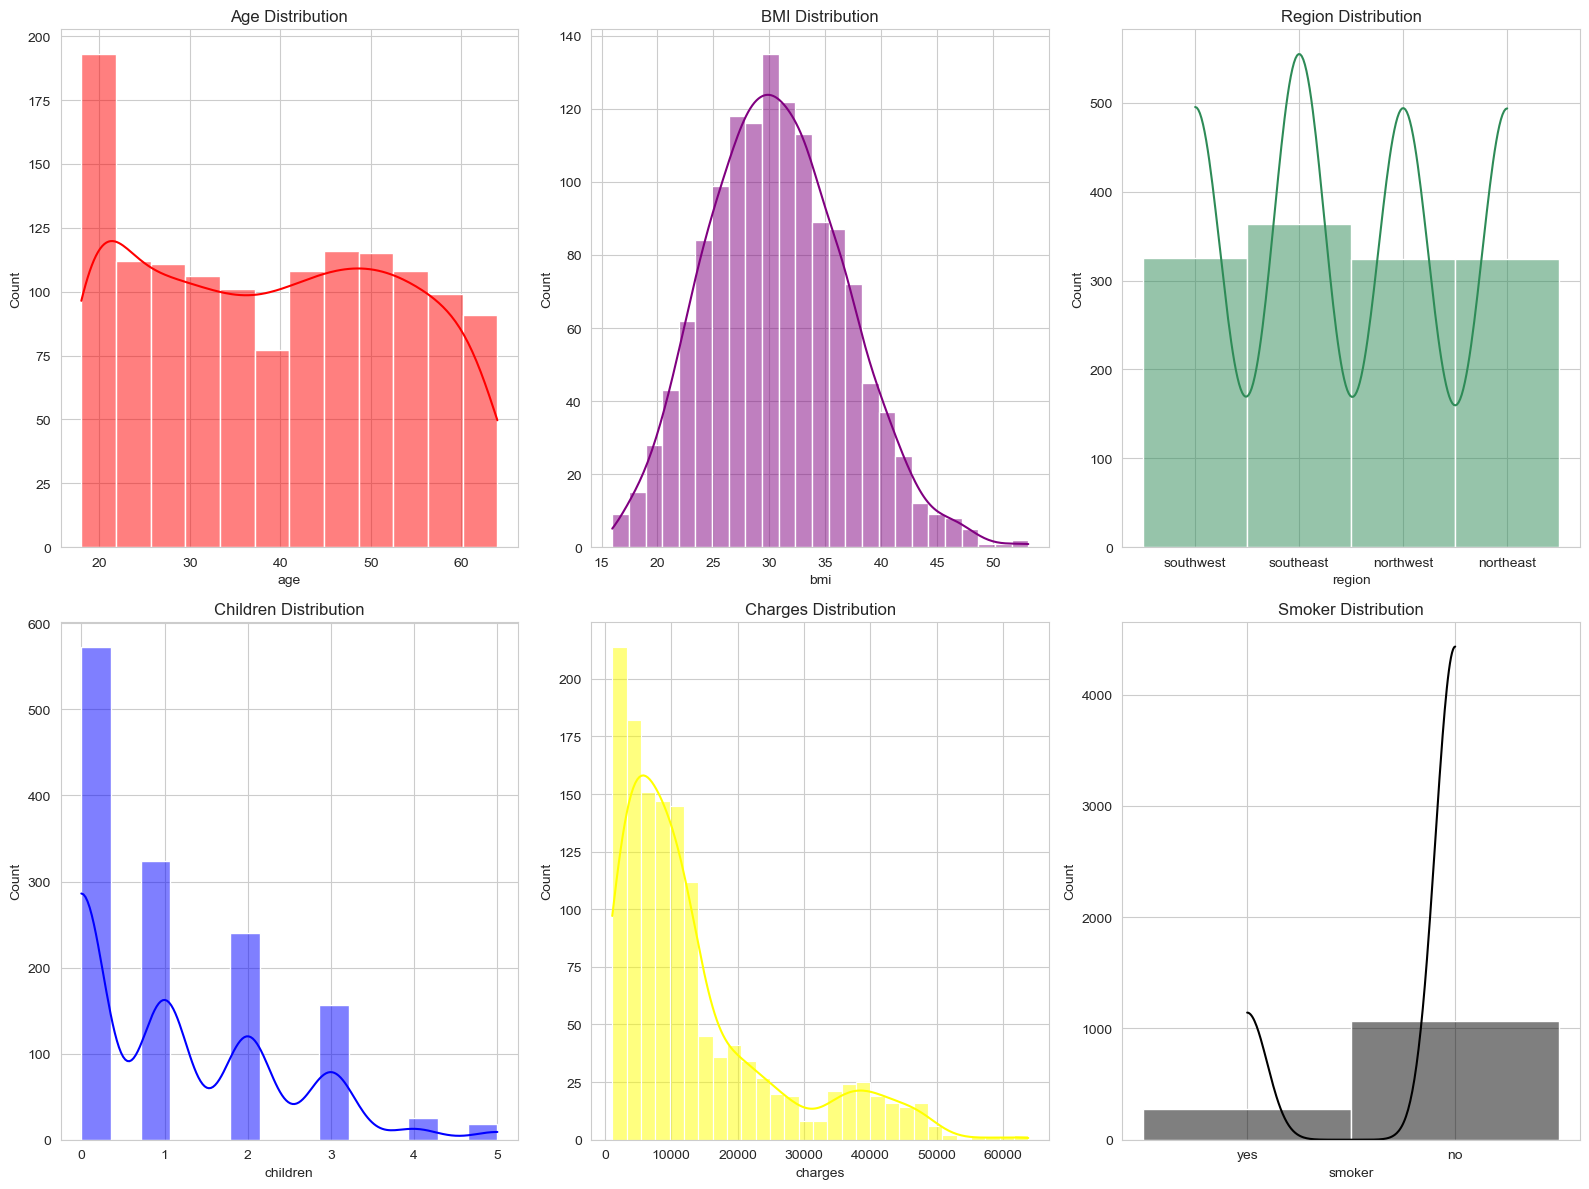

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16,12))

sns.histplot(df["age"], kde = True, ax = axes[0,0], color = "Red")
axes[0,0].set_title("Age Distribution")

sns.histplot(df["bmi"], kde = True, ax = axes[0,1], color = "Purple")
axes[0,1].set_title("BMI Distribution")

sns.histplot(df["region"], kde = True, ax = axes[0,2], color ="Seagreen")
axes[0,2].set_title("Region Distribution")

sns.histplot(df["children"], kde = True, ax = axes[1,0], color = "Blue")
axes[1,0].set_title("Children Distribution")

sns.histplot(df["charges"], kde = True, ax = axes[1,1], color ="Yellow")
axes[1,1].set_title("Charges Distribution")

sns.histplot(df["smoker"], kde = True, ax = axes[1,2], color ="Black")
axes[1,2].set_title("Smoker Distribution")


plt.tight_layout()
plt.show()



In [ ]:
for col in ["bmi","charges"]:
    
    Q1, Q2 = df[col].quantile(0.25), df[col].quantile(0.75)
    
    IQR = Q2-Q1
    
    lower, upper = Q1 - 1.5 * IQR, Q2 + 1.5 * IQR

    n_out = ((df[col]<lower) | (df[col] > upper)).sum()

    print(f"{col}: bounds = ({lower:.1f},{upper:.1f}, ouliers = {n_out} ({n_out/len(df)*100:.1f}%))")

bmi: bounds = (13.7,47.3, ouliers = 9 (0.7%))
charges: bounds = (-13120.7,34524.8, ouliers = 139 (10.4%))


In [ ]:
df.groupby("smoker")["charges"].agg(["mean", "median", "count", "std"])

,mean,median,count,std
smoker,,,,
no,8440.660307,7345.72660,1063,5992.973800
yes,32050.231832,34456.34845,274,11541.547176


In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "underweight"

    elif 18.5 <= bmi < 25:
        return "normal"

    elif 25 <= bmi < 30:
        return "overweight"

    else:
        return "obese"

In [ ]:
df["bmi_category"] = df["bmi"].apply(bmi_category)

In [ ]:
df.head(10)

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,overweight
1,18,male,33.770,1,no,southeast,1725.55230,obese
2,28,male,33.000,3,no,southeast,4449.46200,obese
3,33,male,22.705,0,no,northwest,21984.47061,normal
4,32,male,28.880,0,no,northwest,3866.85520,overweight
5,31,female,25.740,0,no,southeast,3756.62160,overweight
6,46,female,33.440,1,no,southeast,8240.58960,obese
7,37,female,27.740,3,no,northwest,7281.50560,overweight
8,37,male,29.830,2,no,northeast,6406.41070,overweight
9,60,female,25.840,0,no,northwest,28923.13692,overweight


In [ ]:
df["bmi_category"].value_counts()

bmi_category
obese          706
overweight     386
normal         225
underweight     20
Name: count, dtype: int64

In [ ]:
df.groupby("bmi_category")["charges"].mean().sort_values().round(2)

bmi_category
underweight     8852.20
normal         10409.34
overweight     10987.51
obese          15572.04
Name: charges, dtype: float64

In [ ]:
#to drop skewness
df["log_charges"] = np.log1p(df["charges"])
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,overweight,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,obese,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,obese,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,normal,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,overweight,8.260455


In [ ]:
df["charges"].skew()

1.5153909108403483

In [ ]:
df["log_charges"].skew()

-0.08955835073325419

### Data Encoding

In [ ]:
df_model = pd.get_dummies(
    df,
    columns =["sex", "smoker", "region", "bmi_category"],
    drop_first =True
    )

print(df_model.columns.to_list())

['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_obese', 'bmi_category_overweight', 'bmi_category_underweight']


In [ ]:
df_model.head()

,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_obese,bmi_category_overweight,bmi_category_underweight
0,19,27.900,0,16884.92400,9.734236,False,True,False,False,True,False,True,False
1,18,33.770,1,1725.55230,7.453882,True,False,False,True,False,True,False,False
2,28,33.000,3,4449.46200,8.400763,True,False,False,True,False,True,False,False
3,33,22.705,0,21984.47061,9.998137,True,False,True,False,False,False,False,False
4,32,28.880,0,3866.85520,8.260455,True,False,True,False,False,False,True,False


### Model Training

In [ ]:
feature_cols = [c for c in df_model.columns if c not in ["charges","log_charges"]]

y = df_model["log_charges"]
if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]

X = df_model[feature_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size =0.2)

In [ ]:
y_test_real = np.expm1(y_test)

candidate_models = {
    "LinearRegression" : LinearRegression(),
    "RandomForest" : RandomForestRegressor(n_estimators = 300, max_depth = 6, n_jobs = -1),
    "GradientBoosting" : GradientBoostingRegressor(n_estimators = 300, max_depth = 3, learning_rate = 0.05) 
}

trained_models = {}
metrics_rows = []

for name, model  in candidate_models.items():

    model.fit(X_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)

    r2 = r2_score(y_test_real, y_pred)
    mae = mean_absolute_error(y_test_real, y_pred)
    rsme = np.sqrt(mean_squared_error(y_test_real, y_pred))

    trained_models[name] = model
    metrics_rows.append({"Model": name, "R2": r2, "MAE": mae, "": rsme})

    print(f"{name} R2:{r2:.4f}, MAE:{mae:.2f}, RSME:{rsme:.2f}")


LinearRegression R2:0.5023, MAE:4220.19, RSME:8362.57
RandomForest R2:0.8855, MAE:1829.77, RSME:4010.76
GradientBoosting R2:0.8761, MAE:1885.96, RSME:4173.13


In [ ]:
results = pd.DataFrame(metrics_rows).sort_values("R2", ascending = False).reset_index(drop = True)

In [ ]:
results.round(3)

,Model,R2,MAE,
0,RandomForest,0.886,1829.769,4010.764
1,GradientBoosting,0.876,1885.963,4173.128
2,LinearRegression,0.502,4220.192,8362.570


In [ ]:
best_model_name = results.loc[0, "Model"]
best_model = trained_models[best_model_name]

In [ ]:
best_model_name

'RandomForest'

### Exporting model

In [ ]:
joblib.dump(best_model, "insurance_model.pkl")
joblib.dump(feature_cols, "model_feature.pkl")
joblib.dump(best_model_name, "model_name.pkl")

['model_name.pkl']